# Convolución 2D de una imagen con un kernel 3x3 ingresado por el usuario

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Hacer un script que cargue una imagen en RGB o en escala de grises, le aplique una convolución con un kernel de 3x3 y muestre un subplot con la imagen original y la imagen filtrada. **El usuario ingresa el kernel.**

## Qué calcula

La fórmula de la clase, tal cual:

$$C(i,j) = \sum_{m=0}^{k-1}\sum_{n=0}^{k-1} I(i+m,\, j+n)\cdot K(m,n)$$

Cada celda de la salida es un producto punto entre el kernel y el parche de imagen que cubre en ese momento, y el **mismo kernel** se reutiliza en todas las posiciones.

## Decisiones de diseño, dichas de frente

- **Es correlación cruzada, como en PyTorch y TensorFlow.** La convolución matemática "verdadera" invierte el kernel antes de aplicarlo; los frameworks de deep learning no lo hacen, y a esto le siguen llamando convolución. El parámetro `invertir_kernel` permite ver la diferencia.
- **RGB: el mismo kernel se aplica a cada canal por separado** (R, G y B) y se vuelven a apilar. No es la "convolución multicanal" de la clase, donde un único kernel de $k\times k\times 3$ suma los tres canales y produce **un solo** mapa de salida. Aquí el objetivo es ver la imagen filtrada a color, no construir un mapa de características.
- **Relleno con ceros (`padding="same"`)** para que la salida tenga el mismo tamaño que la entrada. Con `padding="valid"` no hay relleno y la salida mide $(n-k+1)$, como en la clase.
- **Todo está implementado a mano** con NumPy. SciPy se usa únicamente para comprobar que el resultado es correcto.

In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from fractions import Fraction
from PIL import Image
from scipy.signal import correlate2d, convolve2d

try:
    from ipykernel.kernelbase import StdinNotImplementedError
except ImportError:
    class StdinNotImplementedError(Exception):
        pass

---

## 1. Cargar la imagen (RGB o escala de grises)

Si no se indica ruta, se usa la fotografía de ejemplo que **ya viene incluida con matplotlib**, así que el notebook funciona sin internet y en Colab.

In [2]:
def cargar_imagen(ruta=None, modo="rgb", max_lado=700):
    """Devuelve un arreglo float con valores en [0, 255].

    modo="rgb"  -> forma (alto, ancho, 3)
    modo="gris" -> forma (alto, ancho)
    """
    if ruta is None:
        ruta = os.path.join(matplotlib.get_data_path(), "sample_data", "grace_hopper.jpg")

    imagen = Image.open(ruta).convert("RGB" if modo == "rgb" else "L")

    # Se reduce si es muy grande, solo para que todo corra rapido.
    if max(imagen.size) > max_lado:
        escala = max_lado / max(imagen.size)
        imagen = imagen.resize((round(imagen.width * escala), round(imagen.height * escala)),
                               Image.LANCZOS)

    return np.asarray(imagen, dtype=float)


rgb = cargar_imagen(modo="rgb")
gris = cargar_imagen(modo="gris")
print("RGB :", rgb.shape, "  (alto, ancho, canales)")
print("Gris:", gris.shape, "       (alto, ancho)")

RGB : (600, 512, 3)   (alto, ancho, canales)
Gris: (600, 512)        (alto, ancho)


---

## 2. La convolución, en dos versiones

**La ingenua** es la definición literal, con cuatro ciclos anidados: dos para recorrer la imagen y dos para recorrer el kernel. Es lenta, pero es exactamente la fórmula.

**La vectorizada** hace lo mismo sumando 9 copias desplazadas de la imagen, cada una multiplicada por un elemento del kernel. Da el mismo resultado, muchísimo más rápido.

In [3]:
def convolucion2d_ingenua(img, kernel, padding="same"):
    """Definicion literal: C(i,j) = suma_m suma_n  I(i+m, j+n) * K(m,n)."""
    k = kernel.shape[0]
    if padding == "same":
        img = np.pad(img, k // 2, mode="constant")

    alto, ancho = img.shape[0] - k + 1, img.shape[1] - k + 1
    salida = np.zeros((alto, ancho))

    for i in range(alto):
        for j in range(ancho):
            acumulado = 0.0
            for m in range(k):
                for n in range(k):
                    acumulado += img[i + m, j + n] * kernel[m, n]
            salida[i, j] = acumulado
    return salida


def convolucion2d(img, kernel, padding="same"):
    """La misma formula, vectorizada: se suman k*k copias desplazadas de la imagen."""
    k = kernel.shape[0]
    if padding == "same":
        img = np.pad(img, k // 2, mode="constant")

    alto, ancho = img.shape[0] - k + 1, img.shape[1] - k + 1
    salida = np.zeros((alto, ancho))

    for m in range(k):
        for n in range(k):
            salida += kernel[m, n] * img[m:m + alto, n:n + ancho]
    return salida


def aplicar_filtro(img, kernel, padding="same", invertir_kernel=False):
    """Filtra una imagen en gris (2D) o RGB (3D, canal por canal)."""
    kernel = np.asarray(kernel, dtype=float)
    if invertir_kernel:
        kernel = np.flip(kernel)          # convolucion "verdadera"

    if img.ndim == 2:
        return convolucion2d(img, kernel, padding)

    canales = [convolucion2d(img[..., c], kernel, padding) for c in range(img.shape[2])]
    return np.stack(canales, axis=-1)

### 2.1 Comprobar que está bien

Cuatro verificaciones: el ejemplo numérico de la clase (el `-74` de la diapositiva), la versión ingenua contra la vectorizada, ambas contra SciPy, y el efecto de invertir el kernel.

In [4]:
# 1) El ejemplo de la diapositiva: parche 3x3 con el kernel de centro 8.
parche = np.array([[21, 19, 17], [71, 76, 73], [153, 164, 164]], dtype=float)
kernel_slide = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=float)
resultado_slide = convolucion2d(parche, kernel_slide, padding="valid")[0, 0]
print(f"Ejemplo de la clase: C(0,0) = {resultado_slide:.0f}   (la diapositiva da -74)")
assert resultado_slide == -74

# 2) Ingenua vs vectorizada (en un recorte, porque la ingenua es lenta).
K_prueba = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
recorte = gris[:60, :60]
print("Ingenua == vectorizada          :", np.allclose(convolucion2d_ingenua(recorte, K_prueba),
                                                     convolucion2d(recorte, K_prueba)))

# 3) Contra SciPy, en gris y en RGB.
print("Vectorizada == SciPy (gris)     :", np.allclose(aplicar_filtro(gris, K_prueba),
                                                      correlate2d(gris, K_prueba, mode="same")))
ref_rgb = np.stack([correlate2d(rgb[..., c], K_prueba, mode="same") for c in range(3)], axis=-1)
print("Vectorizada == SciPy (RGB)      :", np.allclose(aplicar_filtro(rgb, K_prueba), ref_rgb))

# 4) Con el kernel invertido se obtiene la convolucion matematica verdadera.
print("Kernel invertido == convolve2d  :", np.allclose(aplicar_filtro(gris, K_prueba, invertir_kernel=True),
                                                      convolve2d(gris, K_prueba, mode="same")))

# Tamano de la salida segun el relleno.
print()
print(f"Entrada           : {gris.shape}")
print(f"padding='same'    : {aplicar_filtro(gris, K_prueba, 'same').shape}   (mismo tamano)")
print(f"padding='valid'   : {aplicar_filtro(gris, K_prueba, 'valid').shape}   (n - k + 1 = {gris.shape[0]-2} x {gris.shape[1]-2})")

Ejemplo de la clase: C(0,0) = -74   (la diapositiva da -74)
Ingenua == vectorizada          : True
Vectorizada == SciPy (gris)     : True
Vectorizada == SciPy (RGB)      : True
Kernel invertido == convolve2d  : True

Entrada           : (600, 512)
padding='same'    : (600, 512)   (mismo tamano)
padding='valid'   : (598, 510)   (n - k + 1 = 598 x 510)


---

## 3. Que el usuario ingrese el kernel

Hay dos maneras de dar el kernel: **escribir sus 9 valores fila por fila**, o **elegir uno predefinido** de una lista. Al escribirlo se acepta:

- números separados por espacios o por comas: `-1 0 1` o `-1, 0, 1`
- decimales: `0.5`
- fracciones: `1/9` (cómodo para escribir un desenfoque)

Si una fila es inválida, se explica el error y se vuelve a pedir; no se cae.

In [5]:
KERNELS_PREDEFINIDOS = {
    "identidad":            np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float),
    "desenfoque (promedio)": np.ones((3, 3)) / 9,
    "desenfoque gaussiano": np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16,
    "nitidez (sharpen)":    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "bordes (laplaciano)":  np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=float),
    "bordes verticales (Sobel)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "bordes horizontales (Sobel)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
    "relieve (emboss)":     np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
}


def parsear_fila(texto):
    """Convierte '-1 0 1', '-1, 0, 1' o '1/9 1/9 1/9' en tres numeros."""
    fichas = texto.replace(",", " ").split()
    if len(fichas) != 3:
        raise ValueError(f"se esperaban 3 numeros y se recibieron {len(fichas)}")
    try:
        return [float(Fraction(ficha)) for ficha in fichas]
    except (ValueError, ZeroDivisionError):
        raise ValueError("solo se aceptan numeros, decimales (0.5) o fracciones (1/9)")


def pedir_kernel():
    """Pide el kernel por teclado. Devuelve un arreglo 3x3."""
    nombres = list(KERNELS_PREDEFINIDOS)
    print("Kernel 3x3. Elige una opcion:")
    print("  0) Escribir mis propios valores")
    for i, nombre in enumerate(nombres, start=1):
        print(f"  {i}) {nombre}")

    while True:
        opcion = input("Opcion: ").strip()
        if opcion == "0" or (opcion.isdigit() and 1 <= int(opcion) <= len(nombres)):
            break
        print(f"  Opcion no valida. Escribe un numero entre 0 y {len(nombres)}.")

    if opcion != "0":
        return KERNELS_PREDEFINIDOS[nombres[int(opcion) - 1]].copy()

    print("Escribe cada fila con 3 numeros (ejemplo: -1 0 1).")
    filas = []
    while len(filas) < 3:
        texto = input(f"Fila {len(filas) + 1}: ")
        try:
            filas.append(parsear_fila(texto))
        except ValueError as error:
            print(f"  Fila invalida: {error}. Intenta de nuevo.")
    return np.array(filas)

In [6]:
# Se prueba solo el analizador de filas, sin teclado.
casos = ["-1 0 1", "-1, 0, 1", "1/9 1/9 1/9", "0.5 0 -0.5", "1 2", "a b c", "1 2 3 4", "1/0 1 1"]
for texto in casos:
    try:
        print(f"{texto!r:>16}  ->  {parsear_fila(texto)}")
    except ValueError as error:
        print(f"{texto!r:>16}  ->  error: {error}")

        '-1 0 1'  ->  [-1.0, 0.0, 1.0]
      '-1, 0, 1'  ->  [-1.0, 0.0, 1.0]
   '1/9 1/9 1/9'  ->  [0.1111111111111111, 0.1111111111111111, 0.1111111111111111]
    '0.5 0 -0.5'  ->  [0.5, 0.0, -0.5]
           '1 2'  ->  error: se esperaban 3 numeros y se recibieron 2
         'a b c'  ->  error: solo se aceptan numeros, decimales (0.5) o fracciones (1/9)
       '1 2 3 4'  ->  error: se esperaban 3 numeros y se recibieron 4
       '1/0 1 1'  ->  error: solo se aceptan numeros, decimales (0.5) o fracciones (1/9)


---

## 4. Mostrar la imagen original y la filtrada

Un kernel puede producir valores negativos o mayores que 255, que no caben en una imagen. La forma de mostrarlos depende del tipo de kernel, y se decide sola según la **suma de sus elementos**:

- **Suma cercana a 1** (desenfoque, nitidez, identidad): el brillo general se conserva y el resultado ya está en escala. Se **recorta** a $[0, 255]$.
- **Suma cercana a 0** (detectores de bordes): las zonas planas dan 0 y los bordes dan valores positivos y negativos. Se **normaliza** por percentiles (1% a 99%) para ver ambos signos, con el gris medio como "sin borde".

El título del gráfico indica cuál se usó.

In [7]:
def preparar_para_mostrar(resultado, kernel, modo="auto"):
    """Lleva el resultado de la convolucion al rango [0, 255] para poder dibujarlo."""
    if modo == "auto":
        modo = "recortar" if abs(kernel.sum()) > 0.5 else "normalizar"

    if modo == "recortar":
        return np.clip(resultado, 0, 255), modo

    bajo, alto = np.percentile(resultado, [1, 99])
    return np.clip((resultado - bajo) / (alto - bajo) * 255, 0, 255), modo


def mostrar_original_y_filtrada(imagen, kernel, padding="same", invertir_kernel=False, visualizacion="auto"):
    """Subplot: imagen original a la izquierda, imagen filtrada a la derecha."""
    resultado = aplicar_filtro(imagen, kernel, padding, invertir_kernel)
    filtrada, modo_usado = preparar_para_mostrar(resultado, kernel, visualizacion)

    es_gris = imagen.ndim == 2
    opciones = dict(cmap="gray", vmin=0, vmax=255) if es_gris else {}

    fig, ejes = plt.subplots(1, 2, figsize=(12, 6.5))
    ejes[0].imshow(imagen.astype(np.uint8), **opciones)
    ejes[0].set_title(f"Imagen original {imagen.shape}")
    ejes[1].imshow(filtrada.astype(np.uint8), **opciones)
    ejes[1].set_title(f"Imagen filtrada {filtrada.shape}\n(visualizacion: {modo_usado})")
    for eje in ejes:
        eje.axis("off")

    nombre_conv = "convolucion verdadera" if invertir_kernel else "correlacion cruzada"
    fig.suptitle(f"Kernel = {kernel.tolist()}   |   suma = {kernel.sum():.2f}   |   {nombre_conv}",
                 fontsize=10)
    plt.tight_layout()
    plt.show()
    return resultado

---

## 5. El script interactivo

Esta función junta todo: pide la ruta de la imagen, el modo (RGB o gris) y el kernel, y muestra el subplot.

Si se ejecuta en un entorno **sin teclado** (por ejemplo "ejecutar todo" en modo automático), no se queda esperando: avisa y usa un kernel de ejemplo.

In [8]:
def ejecutar_interactivo(ruta=None, modo=None, kernel=None):
    """Pide por teclado lo que no se haya dado como argumento y muestra el resultado."""
    try:
        if ruta is None:
            while True:
                texto = input("Ruta de la imagen (Enter = fotografia de ejemplo): ").strip()
                if texto == "" or os.path.exists(texto):
                    ruta = texto or None
                    break
                print("  No encuentro ese archivo. Intenta de nuevo.")

        if modo is None:
            while True:
                modo = input("Modo de la imagen [rgb/gris] (Enter = rgb): ").strip().lower() or "rgb"
                if modo in ("rgb", "gris"):
                    break
                print("  Escribe 'rgb' o 'gris'.")

        if kernel is None:
            kernel = pedir_kernel()

    except (EOFError, StdinNotImplementedError):
        print("\nNo hay entrada por teclado disponible en este entorno.")
        print("Se usa un ejemplo: modo=rgb, kernel de bordes verticales (Sobel).")
        modo = modo or "rgb"
        kernel = KERNELS_PREDEFINIDOS["bordes verticales (Sobel)"] if kernel is None else kernel

    kernel = np.asarray(kernel, dtype=float)
    print(f"\nKernel elegido:\n{kernel}")
    imagen = cargar_imagen(ruta, modo)
    mostrar_original_y_filtrada(imagen, kernel)
    return kernel

> **Nota sobre esta celda.** Al ejecutarla, Jupyter te pide cada dato en una caja de texto. Las salidas que se ven guardadas abajo vienen de una corrida de ejemplo con las respuestas escritas de antemano (se ve el eco de cada una), incluyendo una fila inválida a propósito (`-1 0`) para mostrar cómo se maneja el error.

Ruta de la imagen (Enter = fotografia de ejemplo): 
Modo de la imagen [rgb/gris] (Enter = rgb): rgb
Kernel 3x3. Elige una opcion:
  0) Escribir mis propios valores
  1) identidad
  2) desenfoque (promedio)
  3) desenfoque gaussiano
  4) nitidez (sharpen)
  5) bordes (laplaciano)
  6) bordes verticales (Sobel)
  7) bordes horizontales (Sobel)
  8) relieve (emboss)
Opcion: 0
Escribe cada fila con 3 numeros (ejemplo: -1 0 1).
Fila 1: -1 0
  Fila invalida: se esperaban 3 numeros y se recibieron 2. Intenta de nuevo.
Fila 1: -1 0 1
Fila 2: -2 0 2
Fila 3: -1 0 1

Kernel elegido:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]


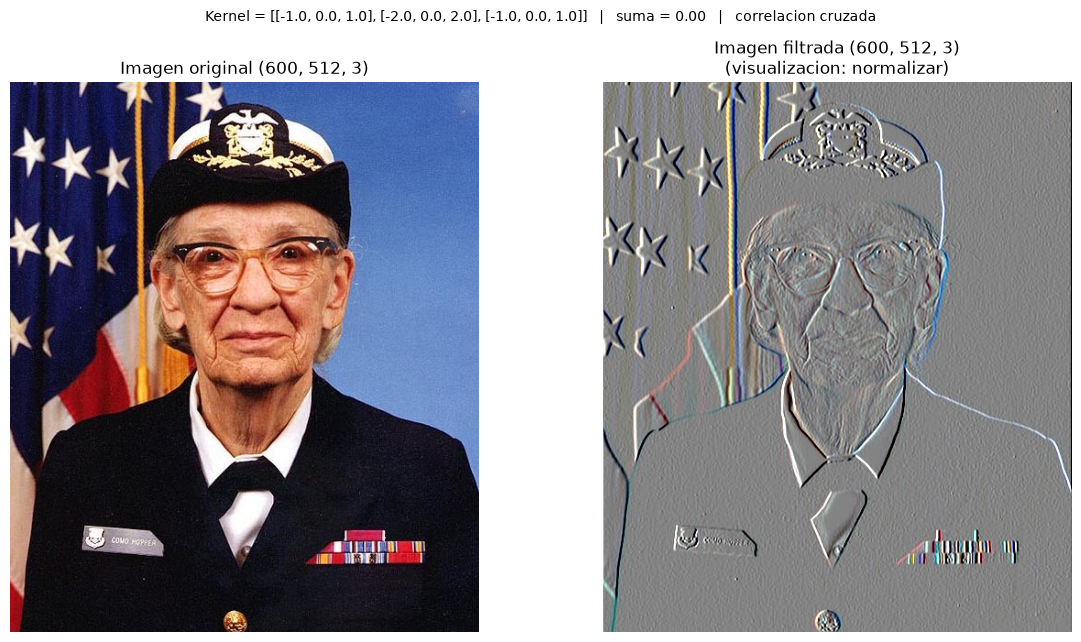

In [9]:
kernel_ingresado = ejecutar_interactivo()

---

## 6. Galería: el mismo kernel de 3x3, ocho comportamientos distintos

Como demostración, los ocho kernels predefinidos sobre la fotografía en color. Lo único que cambia entre un panel y otro son los 9 números del kernel.

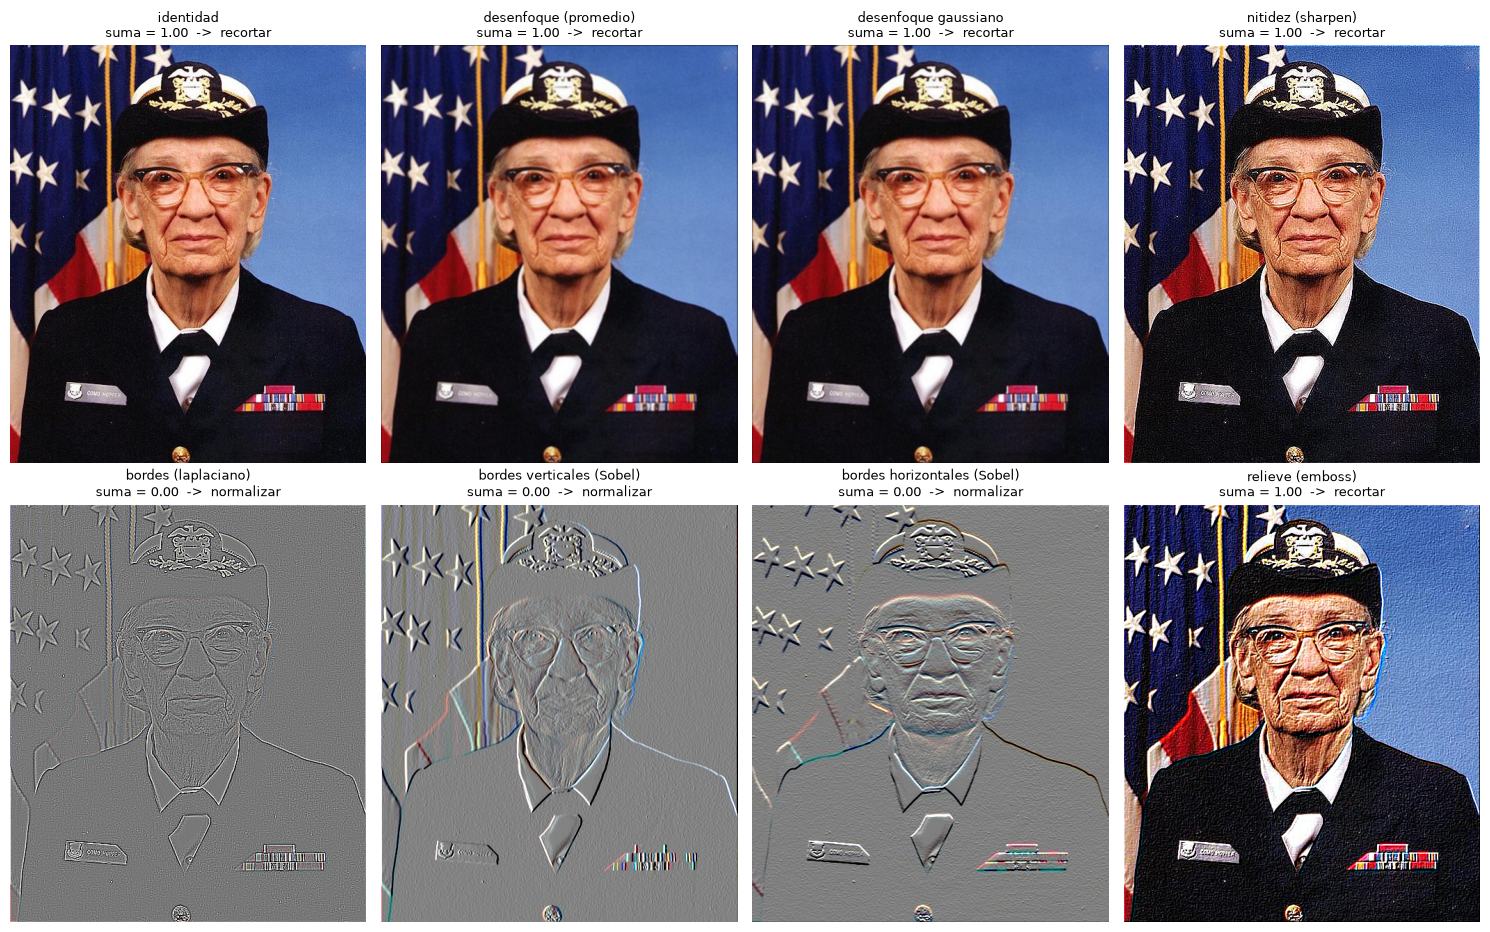

In [10]:
fig, ejes = plt.subplots(2, 4, figsize=(15, 9.5))

for eje, (nombre, kernel) in zip(ejes.ravel(), KERNELS_PREDEFINIDOS.items()):
    resultado = aplicar_filtro(rgb, kernel)
    filtrada, modo_usado = preparar_para_mostrar(resultado, kernel)
    eje.imshow(filtrada.astype(np.uint8))
    eje.set_title(f"{nombre}\nsuma = {kernel.sum():.2f}  ->  {modo_usado}", fontsize=9)
    eje.axis("off")

plt.tight_layout()
plt.show()

Lo que se ve, y por qué:

- **Identidad**: la imagen no cambia. Es el kernel con un 1 en el centro y ceros alrededor, que copia cada píxel tal cual.
- **Desenfoques**: cada píxel pasa a ser el promedio (o un promedio ponderado) de su vecindario, así que los detalles finos se suavizan.
- **Nitidez**: refuerza el píxel central y le resta sus vecinos, así que resalta las diferencias locales.
- **Bordes (Laplaciano y Sobel)**: dan cerca de cero donde la imagen es uniforme y valores grandes donde hay un cambio brusco. El de Sobel vertical resalta las líneas verticales (las franjas de la bandera) y el horizontal, las horizontales.
- **Relieve**: mezcla la imagen con un efecto de iluminación lateral.

---

## 7. Dos observaciones sobre los kernels de la clase

### 7.1 El kernel "sharpen" de la diapositiva en realidad detecta bordes

El kernel de la diapositiva, con un 8 al centro y -1 alrededor, **suma 0**. Un kernel que suma 0 da cero en toda zona uniforme, así que lo que produce no es la imagen más nítida sino **solo sus bordes**. Es el Laplaciano, y en la galería de arriba se ve como tal.

Para *afilar* de verdad hay que **conservar la imagen** y sumarle los bordes, y eso equivale a un kernel que suma 1. Se comprueba: identidad + bordes es exactamente el kernel de nitidez con un 9 al centro.

In [11]:
identidad = KERNELS_PREDEFINIDOS["identidad"]
laplaciano = KERNELS_PREDEFINIDOS["bordes (laplaciano)"]
nitidez_9 = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], dtype=float)

print("suma del kernel de la diapositiva (centro 8):", laplaciano.sum(), " -> detecta bordes")
print("suma del kernel de nitidez (centro 9)       :", nitidez_9.sum(), " -> conserva la imagen")
print("identidad + laplaciano == nitidez (centro 9):", np.allclose(identidad + laplaciano, nitidez_9))

# Por linealidad de la convolucion, aplicar los kernels por separado y sumar da lo mismo.
directa = aplicar_filtro(gris, nitidez_9)
por_partes = aplicar_filtro(gris, identidad) + aplicar_filtro(gris, laplaciano)
print("nitidez == imagen original + sus bordes      :", np.allclose(directa, por_partes))

suma del kernel de la diapositiva (centro 8): 0.0  -> detecta bordes
suma del kernel de nitidez (centro 9)       : 1.0  -> conserva la imagen
identidad + laplaciano == nitidez (centro 9): True
nitidez == imagen original + sus bordes      : True


### 7.2 "Convolución" o correlación cruzada: cuándo importa el orden del kernel

Invertir el kernel (girarlo 180°) solo cambia algo si el kernel **no es simétrico**. Para un desenfoque da igual; para un detector de bordes, invertirlo cambia el signo del resultado.

In [12]:
sobel = KERNELS_PREDEFINIDOS["bordes verticales (Sobel)"]
desenfoque = KERNELS_PREDEFINIDOS["desenfoque gaussiano"]

for nombre, kernel in [("desenfoque gaussiano (simetrico)", desenfoque),
                       ("Sobel vertical (asimetrico)", sobel)]:
    cruzada = aplicar_filtro(gris, kernel)
    verdadera = aplicar_filtro(gris, kernel, invertir_kernel=True)
    print(f"{nombre:<34} misma salida: {np.allclose(cruzada, verdadera)}"
          f"   salida opuesta: {np.allclose(cruzada, -verdadera)}")

desenfoque gaussiano (simetrico)   misma salida: True   salida opuesta: False
Sobel vertical (asimetrico)        misma salida: False   salida opuesta: True


Para el kernel de Sobel la convolución verdadera da **exactamente el negativo** de la correlación cruzada: los mismos bordes con el contraste invertido. Por eso, en una red que aprende sus propios pesos, no importa cuál de las dos se use: si hiciera falta el kernel invertido, la red simplemente aprendería el invertido.

---

## 8. Conclusiones

**Un kernel es solo 9 números, y esos números deciden todo.** Con el mismo código y la misma imagen, cambiar los 9 valores produce desde una copia idéntica hasta un mapa de bordes o un efecto de relieve. Ese es el paso conceptual hacia las redes convolucionales: **en una CNN esos 9 números no se eligen a mano, se aprenden** con el mismo descenso de gradiente de los ejercicios de la neurona.

**La convolución es un producto punto repetido.** Cada píxel de salida sale de multiplicar el kernel por un parche y sumar, y el mismo kernel se reutiliza en toda la imagen. Esa reutilización, la compartición de parámetros, es la razón por la que una capa convolucional necesita muy pocos pesos comparada con una capa totalmente conectada.

**Los resultados se pueden verificar.** La implementación a mano coincide con SciPy en gris y en RGB, reproduce el `-74` de la diapositiva, y la versión con ciclos anidados coincide con la vectorizada.